In [ ]:
import torch
import torchvision
from torch import nn
from torch.utils.data import DataLoader
from torchvision.transforms import v2
import matplotlib.pyplot as plt

device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
print(f"Using {device} device")

# Data (Step 2)
transform = v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])

training_data = torchvision.datasets.MNIST(root="data", train=True, download=True, transform=transform)
test_data = torchvision.datasets.MNIST(root="data", train=False, download=True, transform=transform)

batch_size = 64
train_dataloader = DataLoader(training_data, batch_size=batch_size, shuffle=True)
test_dataloader = DataLoader(test_data, batch_size=batch_size)

# Model (Step 3)
class MNISTClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.linear_relu_stack = nn.Sequential(
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 10),
        )

    def forward(self, x):
        x = self.flatten(x)
        logits = self.linear_relu_stack(x)
        return logits

# Loss and optimizer (Step 4)
model = MNISTClassifier().to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.1)

Using cuda device


100%|██████████| 9.91M/9.91M [00:01<00:00, 5.81MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 135kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.29MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 10.5MB/s]


In [ ]:
def train_one_epoch(model, dataloader, loss_fn, optimizer, device):

    total_loss = 0.0
    model.train()

    for images, labels in dataloader:
        images = images.to(device)
        labels = labels.to(device)
        loss = loss_fn(model(images), labels)
        total_loss += loss.item()

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    total_loss = total_loss / len(dataloader)
    return total_loss

list_of_losses = []
def train_count_epoch():
    epochs = 5
    for epoch in range(epochs):
        average_loss =train_one_epoch(model, train_dataloader, loss_fn, optimizer, device)
        print("Epoch number:",(epoch+1))
        print("Average loss:",average_loss)
        list_of_losses.append(average_loss)

train_count_epoch()
print(list_of_losses)

Epoch number: 1
Average loss: 0.5146704259425846
Epoch number: 2
Average loss: 0.194497450568608
Epoch number: 3
Average loss: 0.1326313734149882
Epoch number: 4
Average loss: 0.10090116717850667
Epoch number: 5
Average loss: 0.0811555125653299
[0.5146704259425846, 0.194497450568608, 0.1326313734149882, 0.10090116717850667, 0.0811555125653299]


In [ ]:
def evaluate_model(model, dataloader, loss_fn, device):

    total_loss = 0.0
    correct_predictions = 0
    model.eval()
    with torch.no_grad():
          for images, labels in dataloader:
              images = images.to(device)
              labels = labels.to(device)
              model_output = (model(images))


              predictions =  torch.argmax(model_output, dim=1)
              correct_predictions += torch.sum(predictions == labels).item()

              loss = loss_fn(model_output, labels)
              total_loss += loss.item()

          total_loss = total_loss / len(dataloader)
          accuracy = correct_predictions / len(dataloader.dataset)
          return total_loss, accuracy

total_loss, accuracy = evaluate_model(model, test_dataloader, loss_fn, device)
print("Total loss:", total_loss)
print("Accuracy:", accuracy*100)

Total loss: 0.09589509349383094
Accuracy: 97.15


Epoch number: 1
Average loss: 0.5056937912554502
Test loss: 0.22442657696854346
Accuracy: 93.52%
Epoch number: 2
Average loss: 0.19414346439561356
Test loss: 0.152555789902308
Accuracy: 95.55%
Epoch number: 3
Average loss: 0.13587481637737517
Test loss: 0.12519294520466334
Accuracy: 96.01%
Epoch number: 4
Average loss: 0.10265408460297056
Test loss: 0.09859103122748328
Accuracy: 96.94%
Epoch number: 5
Average loss: 0.08369702951801913
Test loss: 0.085285675249976
Accuracy: 97.23%
Epoch number: 6
Average loss: 0.06797431249058307
Test loss: 0.07871649426201975
Accuracy: 97.45%
Epoch number: 7
Average loss: 0.057101999575804384
Test loss: 0.07217321408737175
Accuracy: 97.75%
Epoch number: 8
Average loss: 0.04828502267061957
Test loss: 0.07413447158508281
Accuracy: 97.71%
Epoch number: 9
Average loss: 0.041391572603501126
Test loss: 0.07442499619480786
Accuracy: 97.60%
Epoch number: 10
Average loss: 0.035556134965910174
Test loss: 0.06874860360477696
Accuracy: 97.75%


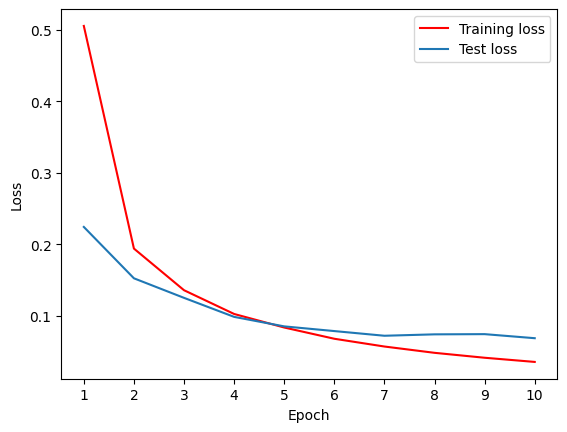

In [ ]:
def epoch_train_eval(learning_rate, epochs):

    model = MNISTClassifier().to(device)
    optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)

    list_of_training_losses = []
    list_of_test_losses = []
    list_of_accuracies = []



    for epoch in range(epochs):
        average_loss = train_one_epoch(model, train_dataloader, loss_fn, optimizer, device)
        test_loss, accuracy = evaluate_model(model, test_dataloader, loss_fn, device)
        list_of_training_losses.append(average_loss)
        list_of_test_losses.append(test_loss)
        list_of_accuracies.append(accuracy)

        print("Epoch number:", (epoch + 1))
        print("Average loss:", average_loss)
        print("Test loss:", test_loss)
        print(f"Accuracy: {accuracy * 100:.2f}%")

    return list_of_training_losses, list_of_test_losses, list_of_accuracies, model

#call
epochs = 10
list_of_training_losses, list_of_test_losses, list_of_accuracies, model = epoch_train_eval(0.1,epochs)

#plt plot 1
plt.plot(range(1, epochs+1), list_of_training_losses, label="Training loss", color="red")
plt.plot(range(1, epochs+1), list_of_test_losses, label="Test loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.xticks(range(1, epochs + 1))
plt.savefig("Train_Eval_loss.png")
plt.show()


Misclassified Images: 225


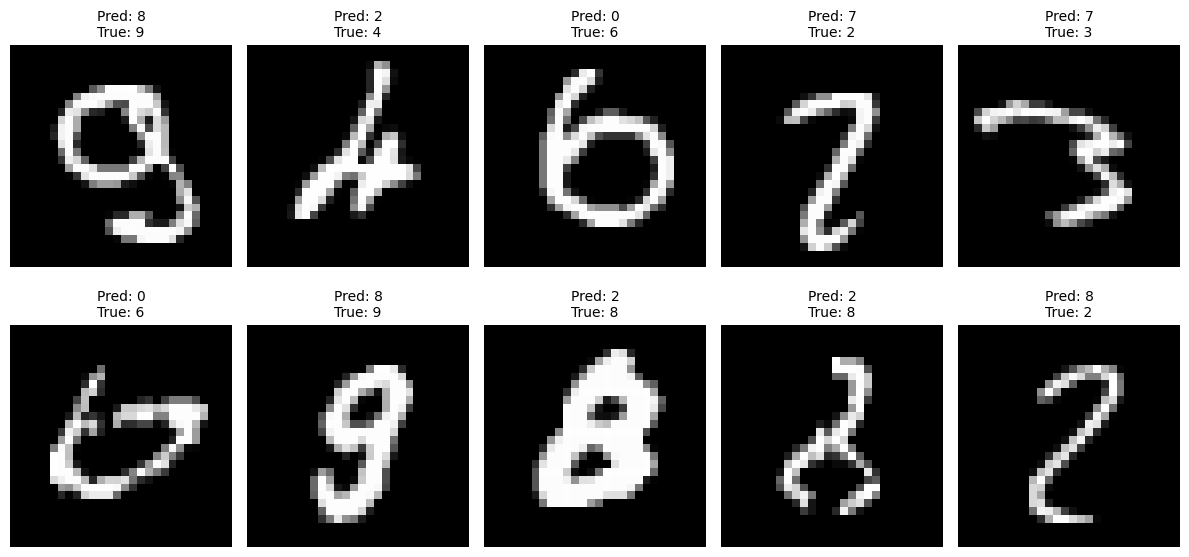

In [ ]:
import numpy as np

def get_misclassified_images(model, dataloader, device):

    misclass_images = []
    misclass_predictions = []
    misclass_labels = []

    model.eval()
    with torch.no_grad():
          for images, labels in dataloader:
              images = images.to(device)
              labels = labels.to(device)
              model_output = (model(images))
              predictions =  torch.argmax(model_output, dim=1)

              images= images.cpu().numpy()
              predictions = predictions.cpu().numpy()
              labels = labels.cpu().numpy()
              misclass_mask = predictions != labels

              misclass_images.extend(images[misclass_mask].tolist())
              misclass_predictions.extend(predictions[misclass_mask].tolist())
              misclass_labels.extend(labels[misclass_mask].tolist())


    return misclass_images, misclass_predictions, misclass_labels

misclass_images, misclass_predictions, misclass_labels = get_misclassified_images(model, test_dataloader, device)
print(f"Misclassified Images: {len(misclass_images)}")

num_to_plot = min(10, len(misclass_images))
fig, axes = plt.subplots(2, 5, figsize=(12, 6))
axes = axes.flatten()

for i in range(num_to_plot):
    img = np.array(misclass_images[i]).squeeze()
    axes[i].imshow(img, cmap='gray')
    axes[i].set_title(f"Pred: {misclass_predictions[i]}\nTrue: {misclass_labels[i]}", fontsize=10)
    axes[i].axis('off')

for i in range(num_to_plot, len(axes)):
    axes[i].axis('off')

plt.tight_layout()
plt.savefig("Misclassified_Samples.png")
plt.show()

In [ ]:
learning_rate_list = [0.001, 0.01, 0.1, 1.0]

learning_rate_result = {
    "learning_rate": [],
    "training_loss": [],
    "test_loss": [],
    "final_accuracy": []
}

epochs = 5

for learning_rate in learning_rate_list:
    list_of_training_losses, list_of_test_losses, list_of_accuracies, _ = epoch_train_eval(learning_rate, epochs)

    learning_rate_result["learning_rate"].append(learning_rate)
    learning_rate_result["training_loss"].append(list_of_training_losses)
    learning_rate_result["test_loss"].append(list_of_test_losses)
    learning_rate_result["final_accuracy"].append(list_of_accuracies[-1])

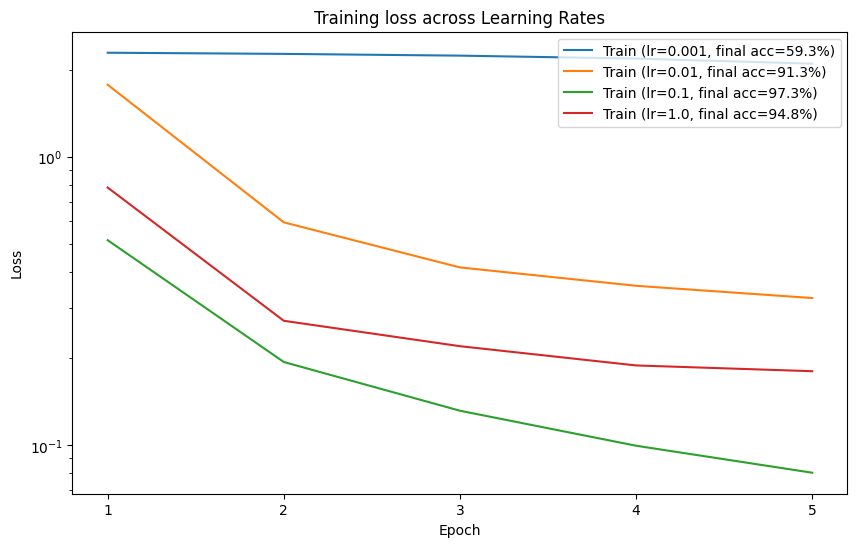

Learning rate 0.001: final accuracy = 0.5926
Learning rate 0.01: final accuracy = 0.9129
Learning rate 0.1: final accuracy = 0.9727
Learning rate 1.0: final accuracy = 0.9478


In [ ]:
plt.figure(figsize=(10, 6))
for lr, train_loss, _ , final_acc in zip(learning_rate_result["learning_rate"],
                                                learning_rate_result["training_loss"],
                                                learning_rate_result["test_loss"],
                                                learning_rate_result["final_accuracy"]):
    plt.plot(range(1, epochs + 1), train_loss, label=f"Train (lr={lr}, final acc={final_acc:.1%})")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend(loc="upper right")
plt.yscale("log")
plt.xticks(range(1, epochs + 1))
plt.title("Training loss across Learning Rates")
plt.savefig("Learning_Rate_Results.png")
plt.show()

for lr, acc in zip(learning_rate_result["learning_rate"],
                   learning_rate_result["final_accuracy"]):
    print(f"Learning rate {lr}: final accuracy = {acc:.4f}")